# Local outlier factor

# for more info click the link below

https://docs.google.com/document/d/1U_ViQPVO8-lBI7sb-sePk6oDnbHhOUx0ZOgXanOxn_M/edit?usp=sharing

# Notes and interview Q and A

https://docs.google.com/document/d/1ikQuAGqhH0eV6MyN6qIVTcr9HsSc_kxJYfL5hLHBIN0/edit?usp=sharing

# Coding

# Import libraries 

In [2]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.datasets import make_blobs                 # Generate synthetic clustered data
from sklearn.neighbors import LocalOutlierFactor        # Local Outlier Factor anomaly detector

# Generate normal data 

In [3]:
X, _ = make_blobs(
    n_samples=500,                                      # Generate 500 normal observations
    centers=[[0, 0], [5, 5]],                           # Create two normal clusters
    cluster_std=[0.5, 1.5],                             # Give the two clusters different densities
    random_state=42                                     # Make the dataset reproducible
)

print("Normal data shape:", X.shape)                    # 500 samples × 2 features

Normal data shape: (500, 2)


# add anomalies 

In [4]:
anomalies = np.array([
    [0, 5],                                             # Artificial anomaly
    [5, 0],                                             # Artificial anomaly
    [10, 0],                                            # Artificial anomaly
    [-5, 5],                                            # Artificial anomaly
    [10, 10]                                            # Artificial anomaly
])

add them to our dataset 

In [5]:
X = np.vstack([
    X,                                                   # Normal observations
    anomalies                                             # Add artificial anomalies
])

print("Final data shape:", X.shape)                     # 505 samples × 2 features

Final data shape: (505, 2)


# Visualize the data

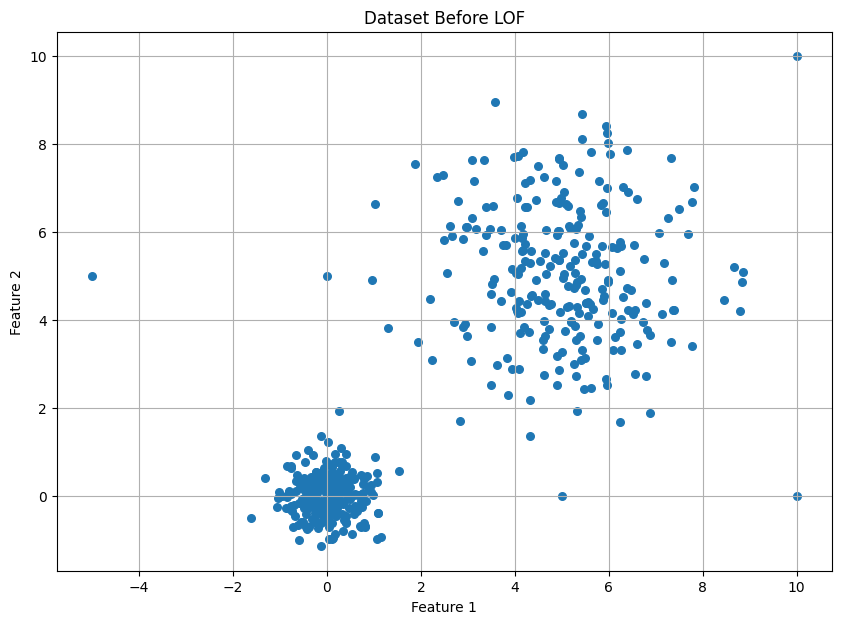

In [6]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30                                                 # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset Before LOF")

plt.grid()
plt.show()

# Create LOF 

In [7]:
lof = LocalOutlierFactor(
    n_neighbors=20,                                     # Compare each point with its 20 nearest neighbors
    contamination=0.01                                  # Expect approximately 1% of observations to be anomalies
)

# Find and predict 

Here's an important difference from Isolation Forest and One-Class SVM.

In [8]:
predictions = lof.fit_predict(
    X                                                     # Fit LOF and classify observations simultaneously
)

# 1 is normal 
# -1 is anomaly 

# Let's inspect the result 

print(predictions[:20])                                  # Display the first 20 predictions

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


# Extract anomalies 

In [9]:
anomaly_mask = predictions == -1                         # Create a Boolean mask for detected anomalies

X_anomalies = X[
    anomaly_mask                                         # Extract observations classified as anomalies
]

print("Detected anomalies:", len(X_anomalies))           # Count detected anomalies

Detected anomalies: 6


# Visualize the detected anomalies 

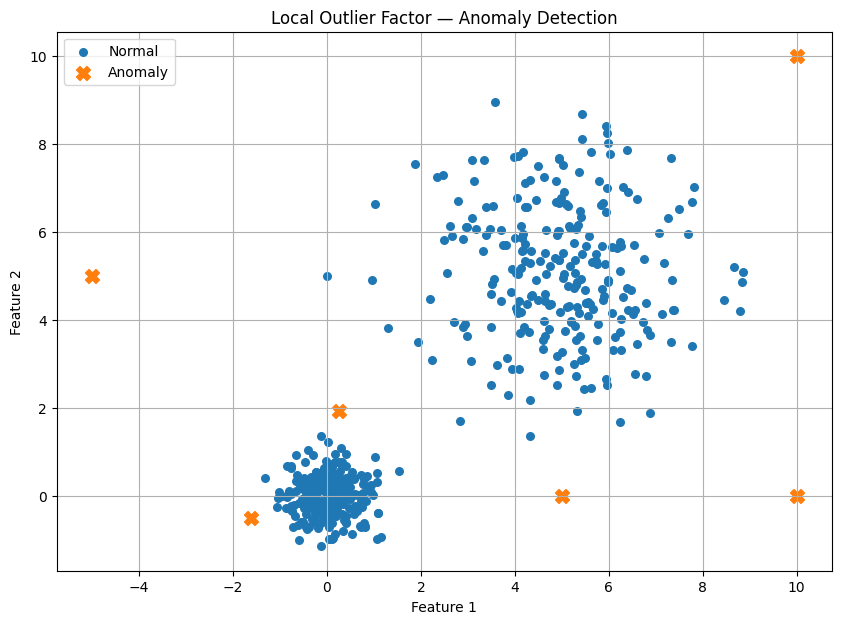

In [10]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X[:, 0],                                             # First feature
    X[:, 1],                                             # Second feature
    s=30,                                                # Normal point size
    label="Normal"
)

plt.scatter(
    X_anomalies[:, 0],                                   # First feature of anomalies
    X_anomalies[:, 1],                                   # Second feature of anomalies
    s=100,                                               # Make anomalies larger
    marker="X",                                          # Use X marker for anomalies
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Local Outlier Factor — Anomaly Detection")

plt.legend()
plt.grid()
plt.show()

# Understand the LOF score 

`LOF provides an important value:`

In [11]:
lof_scores = -lof.negative_outlier_factor_               # Convert sklearn's negative LOF scores into positive LOF-like scores

print(lof_scores[:10])                                   # Display the first 10 LOF scores

[1.01122056 1.03220061 1.09943219 1.51490798 1.0437232  0.96891529
 1.17403136 1.06231909 1.23512805 1.33278143]


# Experiment with n_neighbours 

`This is the main experiment you should perform .`

In [12]:
for n in [5, 10, 20, 30, 50]:

    lof = LocalOutlierFactor(
        n_neighbors=n,                                   # Change the size of the local neighborhood
        contamination=0.01                               # Keep expected anomaly proportion fixed
    )

    predictions = lof.fit_predict(
        X                                                 # Fit LOF and detect anomalies
    )

    print(
        f"n_neighbors={n} → anomalies={sum(predictions == -1)}"
    )

n_neighbors=5 → anomalies=6
n_neighbors=10 → anomalies=6
n_neighbors=20 → anomalies=6
n_neighbors=30 → anomalies=6
n_neighbors=50 → anomalies=6


# Experiment with contamination 


In [13]:
for contamination in [0.01, 0.02, 0.05, 0.10]:

    lof = LocalOutlierFactor(
        n_neighbors=20,                                  # Use 20 nearest neighbors
        contamination=contamination                      # Change expected anomaly proportion
    )

    predictions = lof.fit_predict(
        X                                                 # Fit LOF and detect anomalies
    )

    print(
        f"contamination={contamination} → anomalies={sum(predictions == -1)}"
    )

contamination=0.01 → anomalies=6
contamination=0.02 → anomalies=11
contamination=0.05 → anomalies=26
contamination=0.1 → anomalies=51


# Experiment with contamination 

In [14]:
for contamination in [0.01, 0.02, 0.05, 0.10]:

    lof = LocalOutlierFactor(
        n_neighbors=20,                                  # Use 20 nearest neighbors
        contamination=contamination                      # Change expected anomaly proportion
    )

    predictions = lof.fit_predict(
        X                                                 # Fit LOF and detect anomalies
    )

    print(
        f"contamination={contamination} → anomalies={sum(predictions == -1)}"
    )

contamination=0.01 → anomalies=6
contamination=0.02 → anomalies=11
contamination=0.05 → anomalies=26
contamination=0.1 → anomalies=51
